# Подходит ли фильм для детского профиля?

Датасет: [Rotten Tomatoes movies and critic reviews](https://www.kaggle.com/datasets/stefanoleone992/rotten-tomatoes-movies-and-critic-reviews-dataset) (Kaggle), файл `rotten_tomatoes_movies.csv`.

## 0. Описание задачи

Онлайн-кинотеатры обязаны ставить возрастную маркировку на каждый фильм, а в детском профиле показывать только подходящие фильмы. Модель, которая по описанию и жанру подсказывает, детский ли фильм, экономит время модераторов.

**Задача бинарной классификации** по возрастному рейтингу MPAA:
* **1 — детский**: G, PG;
* **0 — не детский**: PG-13, R, NC-17.

Фильмы без рейтинга (NR) исключаем — для них ответ неизвестен.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.sparse as sp

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, ConfusionMatrixDisplay

%matplotlib inline
sns.set_theme(style='whitegrid')
RANDOM_STATE = 42
CLASS_NAMES = ['не детский', 'детский']
PALETTE = {0: '#2a78d6', 1: '#eb6834'}

## 1. Чтение данных

In [2]:
data = pd.read_csv('data/rotten_tomatoes_movies.csv')
print(data.shape)
data['content_rating'].value_counts()

(17712, 22)


content_rating
R        6377
NR       5474
PG-13    2979
PG       2168
G         676
NC17       38
Name: count, dtype: int64

In [3]:
data = data[data['content_rating'] != 'NR'].reset_index(drop=True)
data['target'] = data['content_rating'].isin(['G', 'PG']).astype(int)

features = [c for c in data.columns if c not in ('rotten_tomatoes_link', 'content_rating', 'target')]
print('Объектов:', len(data), '| признаков:', len(features))
print('Доля пропусков: {:.1%}'.format(data[features].isna().values.mean()))
data['target'].value_counts(normalize=True).rename(index=dict(enumerate(CLASS_NAMES))).round(3)

Объектов: 12238 | признаков: 20
Доля пропусков: 2.7%


target
не детский    0.768
детский       0.232
Name: proportion, dtype: float64

Признаки: 8 числовых (длительность, оценки и число рецензий), 4 категориальных (жанры, студия, два статуса), 2 текстовых (синопсис, консенсус критиков), 6 других (списки режиссёров, сценаристов, актёров, две даты, название).

Из даты выхода берём **год**. Числа рецензий переименуем покороче.

In [4]:
data['release_year'] = pd.to_datetime(data['original_release_date'], errors='coerce').dt.year
data = data.rename(columns={'tomatometer_top_critics_count': 'top_critics_count',
                            'tomatometer_fresh_critics_count': 'fresh_critics_count',
                            'tomatometer_rotten_critics_count': 'rotten_critics_count'})

num_features = ['runtime', 'tomatometer_rating', 'tomatometer_count', 'audience_rating', 'audience_count',
                'top_critics_count', 'fresh_critics_count', 'rotten_critics_count', 'release_year']

## 2. Обучающая и тестовая выборки

Делим 75/25 со стратификацией. Все статистики (медианы, словари, масштаб) дальше считаем только по train.

In [5]:
train, test = train_test_split(data, test_size=0.25, stratify=data['target'], random_state=RANDOM_STATE)
train, test = train.copy(), test.copy()
print('train:', train.shape, ' test:', test.shape)

train: (9178, 24)  test: (3060, 24)


## 3. Визуализация и основные характеристики

In [6]:
train[num_features].describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
runtime,9118.0,103.8,17.5,22.0,92.0,100.5,112.0,254.0
tomatometer_rating,9163.0,55.5,28.3,0.0,32.0,58.0,81.0,100.0
tomatometer_count,9163.0,71.7,75.4,5.0,16.0,42.0,108.0,554.0
audience_rating,9148.0,59.1,20.4,0.0,43.0,61.0,76.0,100.0
audience_count,9148.0,200747.9,2091267.7,5.0,2098.5,8855.5,49240.8,35797635.0
top_critics_count,9178.0,17.9,16.3,0.0,4.0,12.0,31.0,69.0
fresh_critics_count,9178.0,44.0,59.4,0.0,6.0,21.0,56.0,497.0
rotten_critics_count,9178.0,27.6,33.8,0.0,5.0,13.0,37.0,303.0
release_year,8901.0,2000.3,15.6,1915.0,1993.0,2004.0,2012.0,2020.0


In [7]:
train.groupby('target')[num_features].median().T.set_axis(CLASS_NAMES, axis=1)

,не детский,детский
runtime,101.0,98.0
tomatometer_rating,56.0,67.0
tomatometer_count,48.0,28.0
audience_rating,58.0,67.0
audience_count,8772.5,8963.5
top_critics_count,14.0,7.0
fresh_critics_count,22.0,17.0
rotten_critics_count,16.0,7.0
release_year,2006.0,1994.0


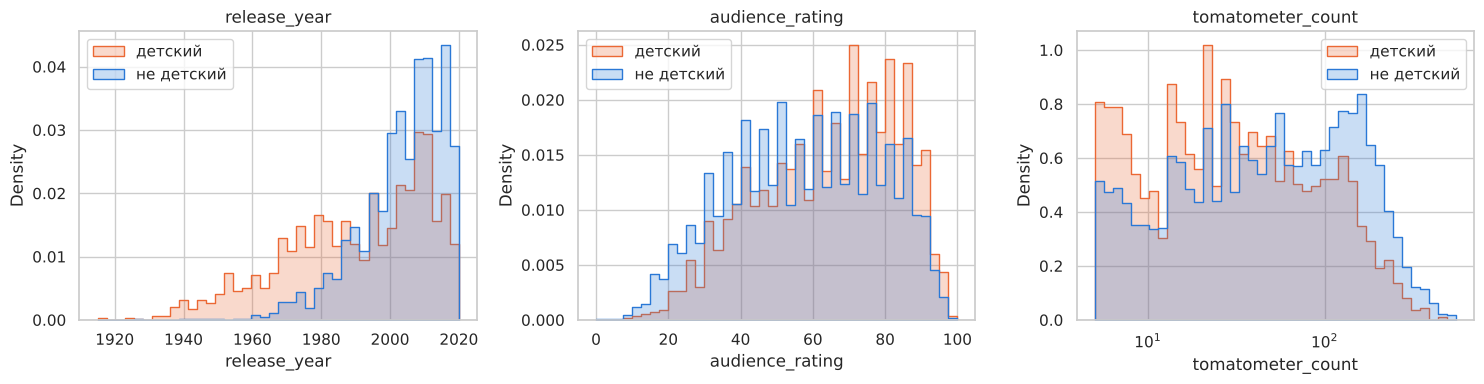

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ['release_year', 'audience_rating', 'tomatometer_count']):
    sns.histplot(data=train, x=col, hue='target', palette=PALETTE, stat='density', common_norm=False,
                 element='step', bins=40, log_scale=(col == 'tomatometer_count'), ax=ax)
    ax.legend(CLASS_NAMES[::-1], title=None)
    ax.set_title(col)
plt.tight_layout()
plt.show()

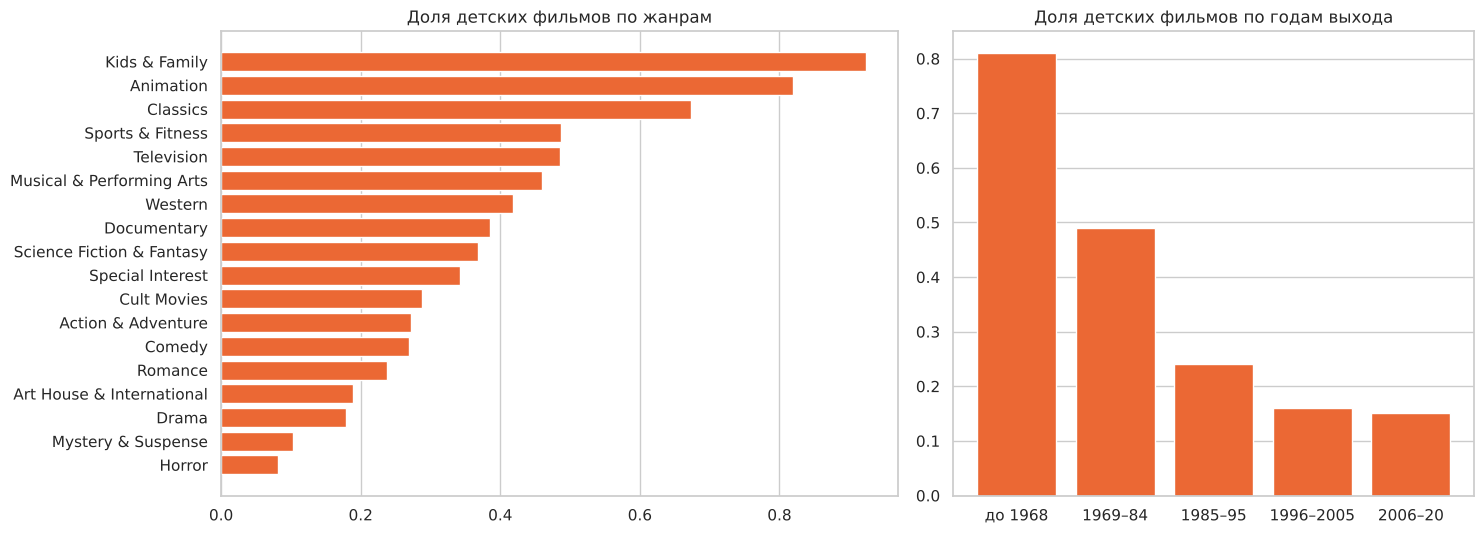

In [9]:
genres = train[['genres', 'target']].dropna().assign(genre=lambda d: d['genres'].str.split(', ')).explode('genre')
g_share = genres.groupby('genre')['target'].agg(['mean', 'size']).query('size >= 50')['mean'].sort_values()
y_share = train.groupby(pd.cut(train['release_year'], [1910, 1968, 1984, 1995, 2005, 2020]), observed=True)['target'].mean()

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={'width_ratios': [1.3, 1]})
axes[0].barh(g_share.index, g_share.values, color=PALETTE[1])
axes[0].set_title('Доля детских фильмов по жанрам')
axes[1].bar(['до 1968', '1969–84', '1985–95', '1996–2005', '2006–20'], y_share.values, color=PALETTE[1])
axes[1].set_title('Доля детских фильмов по годам выхода')
for ax in axes:
    ax.grid(axis='y' if ax is axes[0] else 'x')
plt.tight_layout()
plt.show()

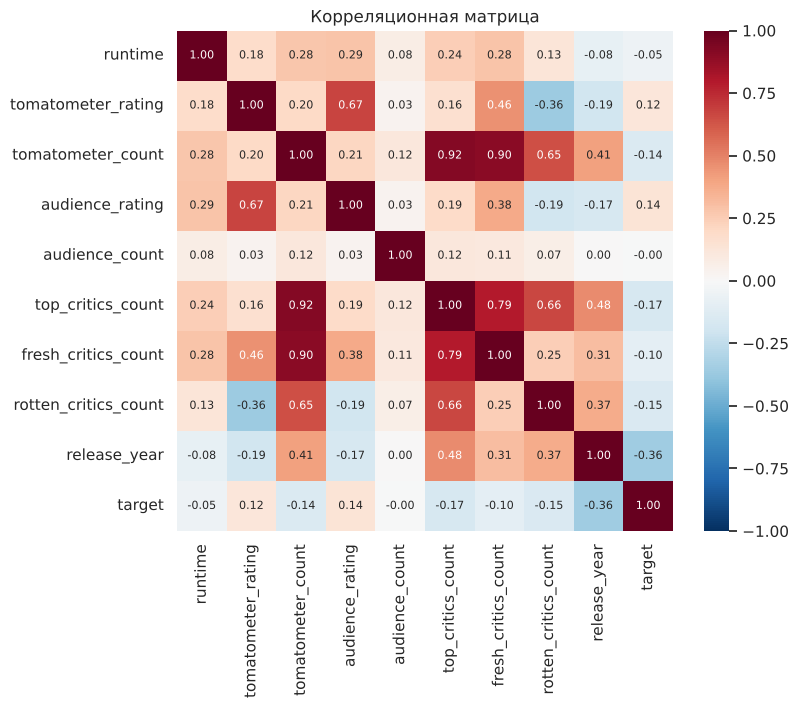

In [10]:
plt.figure(figsize=(8, 6.5))
sns.heatmap(train[num_features + ['target']].corr(), annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1,
            annot_kws={'size': 8})
plt.title('Корреляционная матрица')
plt.show()

**Что видно:**
* **Год выхода** — самый сильный числовой признак: среди фильмов до 1968 г. детских 81%, после 1995 г. — около 15% (рейтинг PG-13 появился только в 1984 г., раньше «пограничные» фильмы получали PG).
* **Жанр** очень информативен: Kids & Family (92% детских) и Animation (82%) почти всегда детские, Horror и Mystery & Suspense — почти никогда.
* У детских фильмов чуть выше оценки зрителей и критиков и меньше рецензий (медиана 28 против 48).
* Корреляции числовых признаков с классом слабые (год: −0.36, остальные меньше 0.2), значит, главная информация — в жанрах и тексте.
* Сильно коррелированы между собой признаки числа рецензий (до 0.92) — вернёмся к этому в п. 12.

## 4. Выбросы

In [11]:
def iqr_share(s):
    q1, q3 = s.quantile([0.25, 0.75])
    return ((s < q1 - 1.5 * (q3 - q1)) | (s > q3 + 1.5 * (q3 - q1))).mean()

pd.DataFrame({'доля выбросов': train[num_features].apply(iqr_share),
              'min': train[num_features].min(), 'медиана': train[num_features].median(),
              'max': train[num_features].max()}).round(3)

,доля выбросов,min,медиана,max
runtime,0.031,22.0,100.5,254.0
tomatometer_rating,0.000,0.0,58.0,100.0
tomatometer_count,0.035,5.0,42.0,554.0
audience_rating,0.000,0.0,61.0,100.0
audience_count,0.141,5.0,8855.5,35797635.0
top_critics_count,0.000,0.0,12.0,69.0
fresh_critics_count,0.084,0.0,21.0,497.0
rotten_critics_count,0.080,0.0,13.0,303.0
release_year,0.032,1915.0,2004.0,2020.0


Выбросов много у `audience_count` (14%: от 5 до 36 млн оценок) и у чисел рецензий (4–8%). Это не ошибки, а популярные фильмы, поэтому эти признаки **логарифмируем**, а не удаляем. По длительности есть явно нетипичные фильмы (22 и 254 минуты) — их удаляем из train (крайние 0.5% с каждой стороны).

In [12]:
log_cols = ['tomatometer_count', 'audience_count', 'fresh_critics_count', 'rotten_critics_count']
for df in (train, test):
    df[log_cols] = np.log1p(df[log_cols])

lo, hi = train['runtime'].quantile([0.005, 0.995])
keep = train['runtime'].isna() | train['runtime'].between(lo, hi)
train = train[keep]
print(f'Удалено из train: {(~keep).sum()} фильмов с длительностью вне [{lo:.0f}, {hi:.0f}] мин')

Удалено из train: 91 фильмов с длительностью вне [71, 177] мин


## 5. Пропущенные значения

In [13]:
text_cols = ['genres', 'production_company', 'movie_info', 'directors', 'authors', 'actors']
miss = train[num_features + text_cols].isna().mean().mul(100).round(2)
miss[miss > 0].sort_values(ascending=False).rename('пропусков в train, %')

authors               5.06
release_year          3.00
production_company    1.09
directors             0.92
movie_info            0.68
runtime               0.66
actors                0.61
audience_rating       0.33
audience_count        0.33
tomatometer_rating    0.17
tomatometer_count     0.17
genres                0.04
Name: пропусков в train, %, dtype: float64

Числовые признаки заполняем **медианой** train, текстовые и списки — **пустой строкой** (то есть «нет информации»).

In [14]:
medians = train[num_features].median()
for df in (train, test):
    df[num_features] = df[num_features].fillna(medians)
    df[text_cols] = df[text_cols].fillna('')

## 6. Категориальные и текстовые признаки

* **жанры** — у фильма их может быть несколько, поэтому делаем по бинарному признаку на каждый жанр;
* **студия** — больше 2000 значений: для kNN заменяем студию на число её фильмов в train (логарифм), для линейной модели — one-hot для студий с ≥ 5 фильмами;
* **режиссёры, сценаристы, актёры** — бинарный признак на каждого человека, встретившегося в ≥ 3 фильмах;
* **синопсис** — TF-IDF (вес каждого слова в тексте).

`critics_consensus` (есть только у 60% фильмов), `tomatometer_status` и `audience_status` (вычисляются из рейтингов) не используем.

In [15]:
genre_list = sorted(set(g for s in train['genres'] for g in s.split(', ') if g))
company_freq = train.loc[train['production_company'] != '', 'production_company'].value_counts()

def make_dense(df):
    X = df[num_features].copy()
    for g in genre_list:
        X['genre_' + g] = df['genres'].str.split(', ').apply(lambda lst: int(g in lst))
    X['company_freq'] = np.log1p(df['production_company'].map(company_freq).fillna(0))
    return X

X_train, X_test = make_dense(train), make_dense(test)
y_train, y_test = train['target'].values, test['target'].values

names = lambda df: df['directors'] + ',' + df['authors'] + ',' + df['actors']
names_vec = CountVectorizer(tokenizer=lambda s: [t.strip() for t in s.split(',') if t.strip()],
                            lowercase=False, min_df=3, binary=True, token_pattern=None)
studio_vec = CountVectorizer(tokenizer=lambda s: [s] if s else [], lowercase=False, min_df=5,
                             binary=True, token_pattern=None)
tfidf = TfidfVectorizer(stop_words='english', ngram_range=(1, 2), min_df=3, max_df=0.5, sublinear_tf=True)

names_train, names_test = names_vec.fit_transform(names(train)), names_vec.transform(names(test))
studio_train, studio_test = studio_vec.fit_transform(train['production_company']), studio_vec.transform(test['production_company'])
text_train, text_test = tfidf.fit_transform(train['movie_info']), tfidf.transform(test['movie_info'])

print('Плотных признаков (числа + жанры + студия):', X_train.shape[1])
print('Имён:', names_train.shape[1], '| студий:', studio_train.shape[1], '| слов синопсиса:', text_train.shape[1])

Плотных признаков (числа + жанры + студия): 31
Имён: 22210 | студий: 215 | слов синопсиса: 21467


## 7. Нормализация

kNN считает расстояния, поэтому признаки нужно привести к одному масштабу: иначе год (~2000) и рейтинги (0–100) полностью заглушат жанры (0/1). Используем стандартизацию по train. TF-IDF уже нормирован.

In [16]:
scaler = StandardScaler().fit(X_train)
X_train_s, X_test_s = scaler.transform(X_train), scaler.transform(X_test)

## 8. Метод ближайших соседей

kNN — базовый метод курса: не требует предположений о форме границы между классами и имеет один основной гиперпараметр $k$. Используем плотные признаки (числа, жанры, студия).

In [17]:
def scores(model, X, y):
    p = model.predict(X)
    return {'ошибка': 1 - accuracy_score(y, p), 'precision': precision_score(y, p),
            'recall': recall_score(y, p), 'F1': f1_score(y, p)}

def report(model, name, Xtr, Xte):
    return pd.DataFrame({(name, 'train'): scores(model, Xtr, y_train),
                         (name, 'test'): scores(model, Xte, y_test)}).T.round(3)

knn = KNeighborsClassifier(n_neighbors=10).fit(X_train_s, y_train)
report(knn, 'kNN, k=10', X_train_s, X_test_s)

ошибка  precision  recall     F1
kNN, k=10 train   0.128      0.856   0.531  0.655
          test    0.148      0.799   0.485  0.604

## 9. Подбор $k$, ошибки и матрицы рассогласования

$k$ выбираем по 5-кратной кросс-валидации на train (тест для выбора использовать нельзя).

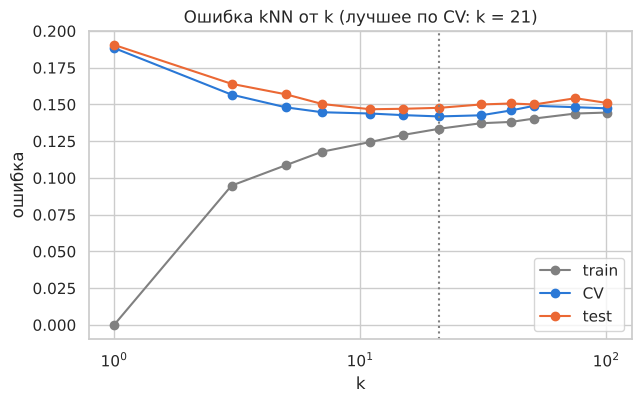

In [18]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
k_values = [1, 3, 5, 7, 11, 15, 21, 31, 41, 51, 75, 101]
rows = []
for k in k_values:
    m = KNeighborsClassifier(n_neighbors=k).fit(X_train_s, y_train)
    rows.append({'k': k,
                 'train': 1 - accuracy_score(y_train, m.predict(X_train_s)),
                 'CV': 1 - cross_val_score(KNeighborsClassifier(n_neighbors=k), X_train_s, y_train, cv=cv).mean(),
                 'test': 1 - accuracy_score(y_test, m.predict(X_test_s))})
k_res = pd.DataFrame(rows).set_index('k')
best_k = int(k_res['CV'].idxmin())

k_res.plot(marker='o', logx=True, figsize=(7, 4), color=['gray', '#2a78d6', '#eb6834'])
plt.axvline(best_k, color='gray', ls=':')
plt.xlabel('k'); plt.ylabel('ошибка'); plt.title(f'Ошибка kNN от k (лучшее по CV: k = {best_k})')
plt.show()

In [19]:
knn = KNeighborsClassifier(n_neighbors=best_k).fit(X_train_s, y_train)
res_knn = report(knn, f'kNN, k={best_k}', X_train_s, X_test_s)
print('Ошибка константы «всегда не детский»: {:.3f}'.format(y_test.mean()))
res_knn

Ошибка константы «всегда не детский»: 0.232


ошибка  precision  recall     F1
kNN, k=21 train   0.133      0.820   0.533  0.646
          test    0.148      0.788   0.498  0.610

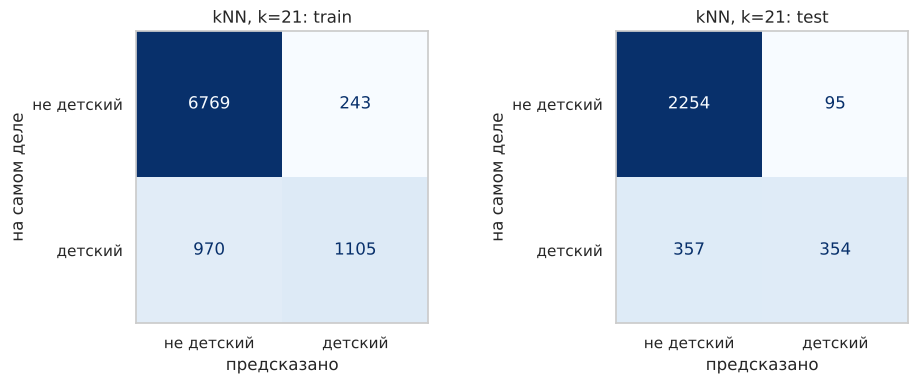

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, X, y, part in [(axes[0], X_train_s, y_train, 'train'), (axes[1], X_test_s, y_test, 'test')]:
    ConfusionMatrixDisplay.from_estimator(knn, X, y, display_labels=CLASS_NAMES, cmap='Blues', colorbar=False, ax=ax)
    ax.set_title(f'kNN, k={best_k}: {part}'); ax.grid(False)
    ax.set_xlabel('предсказано'); ax.set_ylabel('на самом деле')
plt.tight_layout()
plt.show()

**Комментарий.**
* При $k = 1$ ошибка на train равна 0, а на CV — 0.19 (переобучение). С ростом $k$ ошибка на CV падает и выходит на минимум при **$k = 21$**.
* Ошибка на тесте — **0.148** (accuracy 85%), у константы «всегда не детский» — 0.232. Ошибки на train и test близки: переобучения нет.
* Матрица рассогласования: взрослые фильмы модель почти не путает (95 ошибок из 2349), а из 711 детских нашла только половину. Если модель назвала фильм детским, она права в 79% случаев.

## 10. Другие классификаторы

* **Логистическая регрессия** на всех признаках сразу: синопсис (TF-IDF) + имена + студии + плотные признаки. Хорошо работает с большим числом разреженных признаков.
* **Случайный лес** и **градиентный бустинг** на плотных признаках + 100 главных компонент текста (сжатие TF-IDF через SVD).

In [21]:
Xall_train = sp.hstack([text_train, names_train, studio_train, sp.csr_matrix(X_train_s)]).tocsr()
Xall_test = sp.hstack([text_test, names_test, studio_test, sp.csr_matrix(X_test_s)]).tocsr()

svd = TruncatedSVD(n_components=100, random_state=RANDOM_STATE).fit(text_train)
Xsvd_train = np.hstack([X_train_s, svd.transform(text_train)])
Xsvd_test = np.hstack([X_test_s, svd.transform(text_test)])

models = {
    'Логистическая регрессия': (LogisticRegression(C=3, max_iter=3000), Xall_train, Xall_test),
    'Случайный лес': (RandomForestClassifier(n_estimators=500, min_samples_leaf=2, n_jobs=-1,
                                             random_state=RANDOM_STATE), Xsvd_train, Xsvd_test),
    'Градиентный бустинг': (HistGradientBoostingClassifier(random_state=RANDOM_STATE), Xsvd_train, Xsvd_test),
}
results = [res_knn]
for name, (model, A, B) in models.items():
    model.fit(A, y_train)
    results.append(report(model, name, A, B))
pd.concat(results).xs('test', level=1)

,ошибка,precision,recall,F1
"kNN, k=21",0.148,0.788,0.498,0.610
Логистическая регрессия,0.135,0.788,0.571,0.662
Случайный лес,0.140,0.839,0.492,0.621
Градиентный бустинг,0.132,0.798,0.579,0.672


Какие слова синопсиса сильнее всего указывают на класс? Обучим логистическую регрессию только на тексте и посмотрим на её коэффициенты:

In [22]:
lr_text = LogisticRegression(C=3, max_iter=3000).fit(text_train, y_train)
words = tfidf.get_feature_names_out()
order = np.argsort(lr_text.coef_[0])
pd.DataFrame({'→ детский': words[order[::-1][:10]], '→ не детский': words[order[:10]]})

,→ детский,→ не детский
0,dog,drug
1,animals,violent
2,adventure,woman
3,princess,seemingly
4,mr,cop
5,adventures,man
6,animated,gay
7,boy,couple
8,tony,rachel
9,disney,party


**Комментарий.** Логистическая регрессия (0.135) и градиентный бустинг (0.132) немного точнее kNN (0.148) и находят больше детских фильмов (recall 0.57–0.58 против 0.50): они используют текст синопсиса и имена создателей. Слова-сигналы логичны: «детские» — животные, приключения, принцессы, мультфильмы; «взрослые» — наркотики, насилие, криминал.

## 11. Несбалансированность классов

Детских фильмов всего 23%, поэтому модели чаще отвечают «не детский». Попробуем **взвешивание классов** (`class_weight='balanced'`): ошибка на редком классе штрафуется сильнее.

In [23]:
balanced = {
    'Логистическая регрессия, balanced': (LogisticRegression(C=3, max_iter=3000, class_weight='balanced'), Xall_train, Xall_test),
    'Случайный лес, balanced': (RandomForestClassifier(n_estimators=500, min_samples_leaf=2, class_weight='balanced',
                                                       n_jobs=-1, random_state=RANDOM_STATE), Xsvd_train, Xsvd_test),
}
for name, (model, A, B) in balanced.items():
    model.fit(A, y_train)
    results.append(report(model, name, A, B))
pd.concat(results).xs('test', level=1).iloc[[1, 4, 2, 5]]

,ошибка,precision,recall,F1
Логистическая регрессия,0.135,0.788,0.571,0.662
"Логистическая регрессия, balanced",0.145,0.711,0.636,0.671
Случайный лес,0.140,0.839,0.492,0.621
"Случайный лес, balanced",0.133,0.746,0.648,0.694


**Комментарий.** Взвешивание заметно повышает recall по детским фильмам (0.57 → 0.64 у регрессии, 0.49 → 0.65 у леса), но снижает precision: модель чаще ошибочно называет взрослый фильм детским. Для безопасного детского профиля важнее precision, поэтому взвешивание стоит использовать, только если модель служит подсказкой модератору.

## 12. Коррелированные признаки

Сильно коррелированные признаки дублируют друг друга: в kNN такая информация учитывается в расстоянии дважды, а в линейных моделях делает коэффициенты неустойчивыми.

In [24]:
c = X_train[num_features].corr().where(lambda m: np.triu(np.ones(m.shape, dtype=bool), k=1)).stack()
c[c.abs() > 0.7].sort_values(key=abs, ascending=False).round(2)

tomatometer_count  top_critics_count       0.92
                   fresh_critics_count     0.87
top_critics_count  fresh_critics_count     0.80
tomatometer_count  rotten_critics_count    0.74
dtype: float64

`fresh_critics_count` и `rotten_critics_count` полностью выражаются через общее число рецензий и рейтинг критиков. Уберём их и сравним kNN.

In [25]:
drop = ['fresh_critics_count', 'rotten_critics_count']
idx = [i for i, col in enumerate(X_train.columns) if col not in drop]
knn_red = KNeighborsClassifier(n_neighbors=best_k).fit(X_train_s[:, idx], y_train)
pd.concat([res_knn, report(knn_red, f'kNN без {len(drop)} признаков', X_train_s[:, idx], X_test_s[:, idx])])

ошибка  precision  recall     F1
kNN, k=21           train   0.133      0.820   0.533  0.646
                    test    0.148      0.788   0.498  0.610
kNN без 2 признаков train   0.135      0.817   0.528  0.641
                    test    0.149      0.781   0.501  0.610

**Комментарий.** Качество kNN почти не изменилось (ошибка 0.148 → 0.149): удалённые признаки действительно дублировали другие. Модель стала проще без потери точности.

## 13. Выводы

1. Решалась задача: детский фильм (G, PG) или нет (PG-13, R, NC-17). 12 238 фильмов, 23% детских.
2. Главные признаки — **жанр**, **год выхода** и **текст синопсиса**; оценки зрителей и критиков влияют слабо.
3. **kNN** с $k = 21$ (подобрано по кросс-валидации): ошибка на тесте 0.148 против 0.232 у константы.
4. **Лучшие модели** — градиентный бустинг (0.132) и логистическая регрессия (0.135): им помогает текст синопсиса.
5. Модель хорошо узнаёт взрослые фильмы, но пропускает около половины детских. Взвешивание классов повышает их полноту ценой точности.
6. Удаление коррелированных признаков не ухудшило качество, а модель стала проще.